    # Concise Temperature Forecasting Project

Predict temperature six hours ahead from 24 hourly observations. Run each step and commit after successful execution.

Data Source: [MPI-BGC Beutenberg](https://weather.bgc-jena.mpg.de/weather_data.html), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

# 1. Environment and Setup
Fix model settings and create result folders.


In [1]:
import os
import tempfile
from pathlib import Path

# Keep Windows temporary files in the project.
Path(".runtime").mkdir(exist_ok=True)
tempfile.tempdir = str(Path(".runtime").resolve())
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_NUM_INTRAOP_THREADS"] = "4"
os.environ["TF_NUM_INTEROP_THREADS"] = "2"

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
import truststore
truststore.inject_into_ssl()
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

SEED, LOOKBACK, HORIZON = 504, 24, 6
FEATURES = ["T (degC)", "p (mbar)", "rh (%)", "wv (m/s)"]
for folder in ["data", "outputs", "models", "figures"]:
    Path(folder).mkdir(exist_ok=True)
tf.config.experimental.enable_op_determinism()
CONFIG = {"seed": SEED, "lookback": LOOKBACK, "horizon": HORIZON,
          "features": FEATURES, "learning_rate": 0.001, "batch_size": 64,
          "max_epochs": 30, "patience": 5}
Path("outputs/config.json").write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")
print("Runtime versions:", keras.__version__, tf.__version__)

Runtime versions: 3.15.1 2.21.0


# 2. Download and clean
Source: MPI-BGC Beutenberg, CC BY 4.0. Check duplicate conflicts and mask invalid values.

In [2]:
from urllib.request import urlretrieve
from zipfile import ZipFile

names = [f"mpi_roof_{year}{half}" for year in range(2018, 2024) for half in "ab"]
names += ["mpi_roof_2024", "mpi_roof_2025"]
parts = []
for name in names:
    path = Path("data") / f"{name}.zip"
    if not path.exists():
        urlretrieve(f"https://www.bgc-jena.mpg.de/wetter/data/{name}.zip", path)
    with ZipFile(path) as archive:
        with archive.open(f"{name}.csv") as file:
            parts.append(pd.read_csv(file, encoding="latin-1"))

data = pd.concat(parts, ignore_index=True)
data["Date Time"] = pd.to_datetime(data["Date Time"], format="%d.%m.%Y %H:%M:%S")
# Resolve conflicting measurements before deduplication.
repeated = data[data["Date Time"].duplicated(keep=False)]
measurements = data.columns.drop("Date Time")
assert not repeated.groupby("Date Time")[measurements].nunique(dropna=False).gt(1).any().any()
observed = (data.sort_values("Date Time").drop_duplicates("Date Time")
            .set_index("Date Time")[FEATURES].copy())
observed = observed.replace([-9999, np.inf, -np.inf], np.nan)
observed.loc[observed["p (mbar)"] <= 0, "p (mbar)"] = np.nan
observed.loc[~observed["rh (%)"].between(0, 100), "rh (%)"] = np.nan
observed.loc[observed["wv (m/s)"] < 0, "wv (m/s)"] = np.nan
print("Raw/deduplicated rows:", len(data), len(observed))
display(observed.isna().sum().to_frame("Missing count"))

Raw/deduplicated rows: 420782 420631


,Missing count
T (degC),0
p (mbar),0
rh (%),0
wv (m/s),1


# 3. Continuous hourly data

Exact-hour values summarize the preceding ten minutes; retain missing hours without filling. Keep station clock labels.

In [3]:
# Select exact timestamps rather than every sixth row.
hourly_index = pd.date_range(observed.index.min().ceil("h"), observed.index.max().floor("h"), freq="h")
hourly = observed.reindex(hourly_index)
hourly.index.name = "Date Time"
hourly.to_csv("outputs/hourly_observations.csv")
print("Hourly slots/missing hours:", len(hourly), hourly.isna().all(axis=1).sum())

Hourly slots/missing hours: 70128 22


# 4. 归一化、窗口与划分 / Scaling, windows and splits

Inputs t-23h..t, target t+6h; split by target year with a shared four-feature mask.

In [4]:
# Fit on training hours only; keep targets in Celsius.
train_hours = hourly.loc[(hourly.index.year >= 2018) & (hourly.index.year <= 2023)]
mean, std = train_hours.mean(), train_hours.std(ddof=0)
assert np.isfinite(std).all() and (std > 0).all()
scaler = {"features": FEATURES, "means": mean.to_dict(), "stds": std.to_dict()}
Path("outputs/training_scaler.json").write_text(json.dumps(scaler, indent=2), encoding="utf-8")
scaled = ((hourly - mean) / std).to_numpy(dtype=np.float32)

ends = np.arange(LOOKBACK - 1, len(hourly) - HORIZON)
X = np.stack([scaled[t - LOOKBACK + 1:t + 1] for t in ends])
y = hourly[FEATURES[0]].to_numpy()[ends + HORIZON].astype(np.float32)
latest = hourly[FEATURES[0]].to_numpy()[ends].astype(np.float32)
targets = hourly.index[ends + HORIZON]
# Check inputs/targets, not unused t+1..t+5.
valid = np.isfinite(X).all(axis=(1, 2)) & np.isfinite(y)
splits = {}
for name, years in {"train": (2018, 2023), "val": (2024, 2024), "test": (2025, 2025)}.items():
    keep = valid & (targets.year >= years[0]) & (targets.year <= years[1])
    splits[name] = {"X": X[keep], "y": y[keep], "latest": latest[keep], "times": targets[keep]}
assert (targets - hourly.index[ends] == pd.Timedelta(hours=HORIZON)).all()
display(pd.DataFrame({name: {"Samples": len(part["y"])} for name, part in splits.items()}).T)

,Samples
train,52449
val,8784
test,8760


# 5. Persistence validation baseline

Evaluate validation first; test after all models are trained.

In [5]:
def metrics(y, prediction):
    """Errors in degrees Celsius."""
    error = np.asarray(prediction, dtype=float) - np.asarray(y, dtype=float)
    return {"samples": len(error), "mae_c": float(np.abs(error).mean()),
            "rmse_c": float(np.sqrt(np.square(error).mean())), "bias_c": float(error.mean())}

baseline = metrics(splits["val"]["y"], splits["val"]["latest"])
pd.DataFrame([baseline], index=["persistence"]).to_csv("outputs/baseline_validation.csv")
print("Persistence validation:", baseline)

Persistence validation: {'samples': 8784, 'mae_c': 3.3267588744085037, 'rmse_c': 4.36269431262839, 'bias_c': 0.00519922586498894}


# 6. Temperature Dense and training helper

Apply the same plan to all models; restore the best validation-MSE weights.

Epoch 1/30
820/820 - 1s - 1ms/step - loss: 41.6864 - mae: 4.9066 - val_loss: 14.0104 - val_mae: 2.9726
Epoch 2/30
820/820 - 1s - 662us/step - loss: 8.8482 - mae: 2.2855 - val_loss: 6.9169 - val_mae: 2.0437
Epoch 3/30
820/820 - 1s - 613us/step - loss: 6.7124 - mae: 1.9673 - val_loss: 6.2975 - val_mae: 1.9396
Epoch 4/30
820/820 - 1s - 639us/step - loss: 6.2320 - mae: 1.8903 - val_loss: 5.9852 - val_mae: 1.8908
Epoch 5/30
820/820 - 1s - 655us/step - loss: 6.0559 - mae: 1.8633 - val_loss: 5.8306 - val_mae: 1.8622
Epoch 6/30
820/820 - 1s - 634us/step - loss: 5.9567 - mae: 1.8480 - val_loss: 5.7972 - val_mae: 1.8575
Epoch 7/30
820/820 - 1s - 618us/step - loss: 5.8861 - mae: 1.8368 - val_loss: 5.7180 - val_mae: 1.8442
Epoch 8/30
820/820 - 1s - 632us/step - loss: 5.8129 - mae: 1.8251 - val_loss: 5.7257 - val_mae: 1.8488
Epoch 9/30
820/820 - 1s - 628us/step - loss: 5.7672 - mae: 1.8180 - val_loss: 5.5850 - val_mae: 1.8182
Epoch 10/30
820/820 - 1s - 666us/step - loss: 5.7159 - mae: 1.8104 - val_

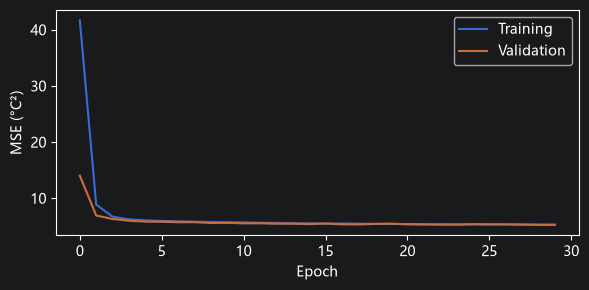

dense_temp Validation: {'samples': 8784, 'mae_c': 1.7624380377781592, 'rmse_c': 2.290138135749034, 'bias_c': -0.10010319130256846, 'parameters': 833, 'training_seconds': 16.184741400000348, 'best_epoch': 29}


In [7]:
def dataset(X, y=None, training=False):
    """Batches with bounded threading."""
    ds = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    return ds.with_options(options).batch(64).prefetch(1)

records = {}
def train_model(name, multivariate=False, recurrent=False):
    """Train and save the best model."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    features = 4 if multivariate else 1
    layers = [keras.layers.Input((LOOKBACK, features))]
    layers += ([keras.layers.GRU(32)] if recurrent else
               [keras.layers.Flatten(), keras.layers.Dense(32, activation="relu")])
    model = keras.Sequential(layers + [keras.layers.Dense(1)])
    model.compile(optimizer=keras.optimizers.Adam(0.001), loss="mse", metrics=["mae"])
    train, val = splits["train"], splits["val"]
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(dataset(train["X"][:, :, :features], train["y"], True),
                        validation_data=dataset(val["X"][:, :, :features], val["y"]),
                        epochs=30, callbacks=[stop],shuffle=False, verbose=2)
    seconds = time.perf_counter() - start
    model.save(f"models/{name}.keras")
    pd.DataFrame(history.history).to_csv(f"outputs/history_{name}.csv", index=False)
    prediction = model.predict(dataset(val["X"][:, :, :features]), verbose=0).ravel()
    records[name] = {**metrics(val["y"], prediction), "parameters": model.count_params(),
                     "training_seconds": seconds, "best_epoch": int(np.argmin(history.history["val_loss"]) + 1)}
    pd.DataFrame(records).T.to_csv("outputs/validation_results.csv")
    plt.figure(figsize=(6, 3))
    plt.plot(history.history["loss"], label="Training")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.xlabel("Epoch"); plt.ylabel("MSE (°C²)"); plt.legend()
    plt.tight_layout(); plt.savefig(f"figures/history_{name}.png"); plt.show()
    print(name, "Validation:", records[name])

train_model("dense_temp")